# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [149]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect('data.sqlite')


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [150]:
# Replace None with your code
query_ca_customers = """
SELECT 
    customerNumber, 
    customerName, 
    contactLastName, 
    contactFirstName, 
    city, 
    state, 
    postalCode, 
    creditLimit
FROM customers
WHERE state = 'CA' AND creditLimit > 25000;
"""
# Execute the query and store the result in a DataFrame
california_high_credit_df = pd.read_sql(query_ca_customers, conn)
# Display the first few rows of the result
california_high_credit_df.head()

,customerNumber,customerName,contactLastName,contactFirstName,city,state,postalCode,creditLimit
0,124,Mini Gifts Distributors Ltd.,Nelson,Susan,San Rafael,CA,97562,210500.00
1,129,Mini Wheels Co.,Murphy,Julie,San Francisco,CA,94217,64600.00
2,161,Technics Stores Inc.,Hashimoto,Juri,Burlingame,CA,94217,84600.00
3,205,Toys4GrownUps.com,Young,Julie,Pasadena,CA,90003,90700.00
4,219,Boards & Toys Co.,Young,Mary,Glendale,CA,92561,11000.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [151]:
# Replace None with your code
q_collectable = """
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       city,
       country,
       CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
"""
df_collectable = pd.read_sql(q_collectable, conn)
df_collectable

,customerNumber,customerName,contactFirstName,contactLastName,city,country,creditLimit
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia,60300.0
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia,117300.0
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria,71700.0
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada,89600.0
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark,120800.0
5,353,Reims Collectables,Paul,Henriot,Reims,France,81100.0
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany,77000.0
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany,0.0
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong,58600.0
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland,69400.0


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [152]:
# Replace None with your code
q_state_credit = """
SELECT state,
       COUNT(*) AS num_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""
df_state_credit = pd.read_sql(q_state_credit, conn)
df_state_credit

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

In [153]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
q_top_customers = """
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers c
JOIN payments p
  ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
df_top_customers = pd.read_sql(q_top_customers, conn)
df_top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [154]:
# Replace None with your code
q_top_customers = """
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers c
JOIN payments p
  ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
df_top_customers = pd.read_sql(q_top_customers, conn)
df_top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

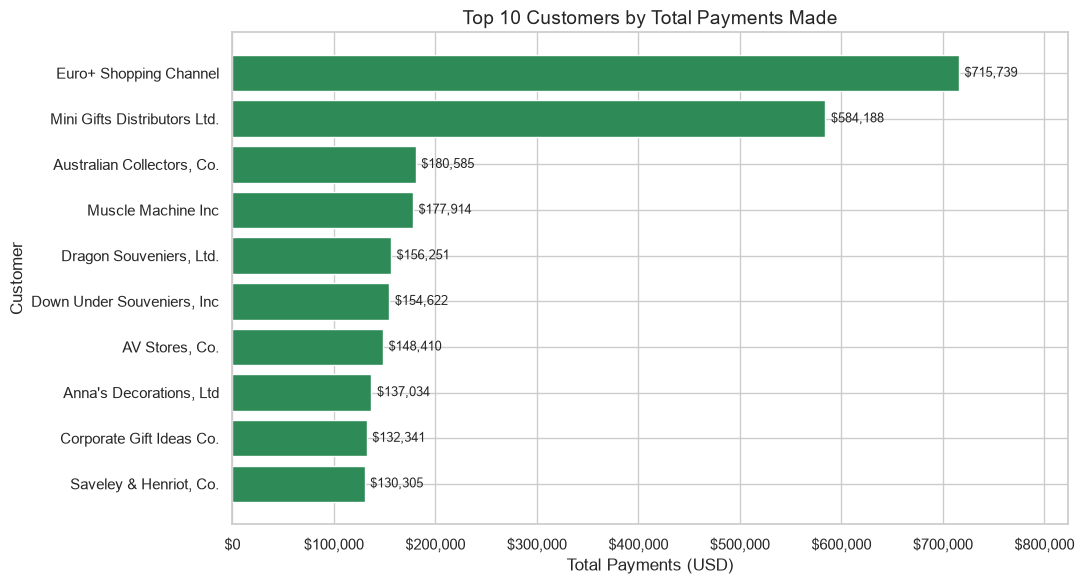

In [155]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments

plot_data = df_top_customers.sort_values("total_payments")      # largest bar at the top

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(plot_data["customerName"], plot_data["total_payments"], color="seagreen")
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in plot_data["total_payments"]], padding=4, fontsize=9)
ax.set_title("Top 10 Customers by Total Payments Made", fontsize=14)
ax.set_xlabel("Total Payments (USD)")
ax.set_ylabel("Customer")
ax.set_xlim(0, plot_data["total_payments"].max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.show() 

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [156]:
# Replace None with you code
q_customer_products = """
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(od.quantityOrdered) AS total_quantity_purchased
FROM customers c
JOIN orders o
  ON c.customerNumber = o.customerNumber
JOIN orderdetails od
  ON o.orderNumber = od.orderNumber
JOIN products p
  ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_quantity_purchased ASC;
"""
df_customer_products = pd.read_sql(q_customer_products, conn)
df_customer_products

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [157]:
# Replace None with your code
q_product_lines = """
SELECT pl.productLine,
       COUNT(DISTINCT p.productCode)        AS number_of_products,
       COALESCE(SUM(od.quantityOrdered), 0) AS total_quantity_ordered
FROM productlines pl
JOIN products p
  ON pl.productLine = p.productLine
LEFT JOIN orderdetails od
  ON p.productCode = od.productCode
GROUP BY pl.productLine
ORDER BY total_quantity_ordered DESC;
"""
df_product_lines = pd.read_sql(q_product_lines, conn)
df_product_lines

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

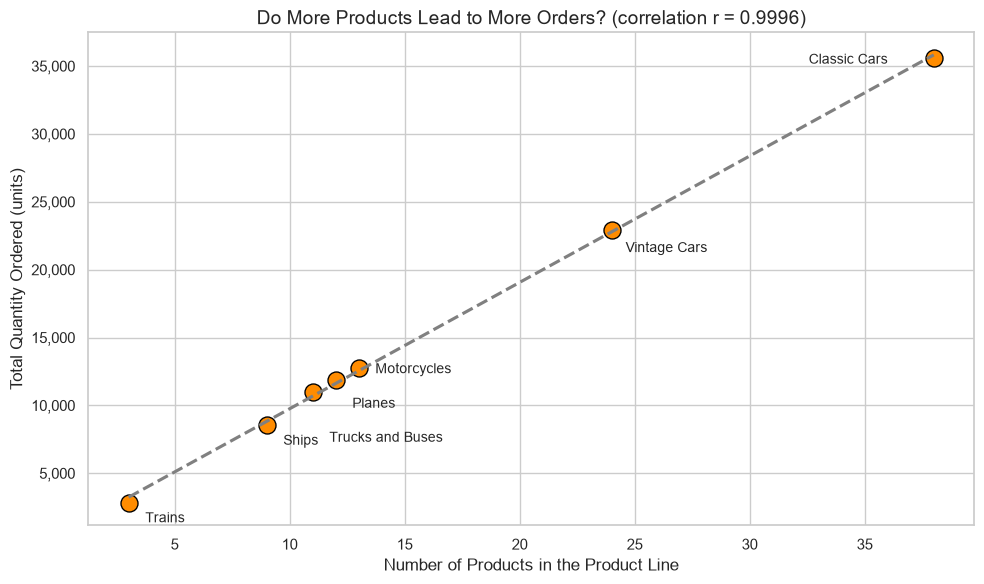

In [158]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_product_lines, x="number_of_products", y="total_quantity_ordered",
                s=150, color="darkorange", edgecolor="black", ax=ax)
sns.regplot(data=df_product_lines, x="number_of_products", y="total_quantity_ordered",
            scatter=False, color="gray", line_kws={"linestyle": "--"}, ci=None, ax=ax)

# Label offsets (in points) are staggered so the three close-together lines do not overlap
label_offsets = {
    "Classic Cars": (-90, -4), "Vintage Cars": (10, -16), "Motorcycles": (12, -4),
    "Planes": (12, -20), "Trucks and Buses": (12, -36), "Ships": (12, -14), "Trains": (12, -14),
}
for _, row in df_product_lines.iterrows():
    ax.annotate(row["productLine"], (row["number_of_products"], row["total_quantity_ordered"]),
                textcoords="offset points", xytext=label_offsets.get(row["productLine"], (8, 6)), fontsize=10)

corr = df_product_lines["number_of_products"].corr(df_product_lines["total_quantity_ordered"])
ax.set_title(f"Do More Products Lead to More Orders? (correlation r = {corr:.4f})", fontsize=14)
ax.set_xlabel("Number of Products in the Product Line")
ax.set_ylabel("Total Quantity Ordered (units)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:,.0f}"))
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I used a scatter plot because the question is about the relationship between two numbers: how many products
a product line has and how many units customers ordered from it. Each dot is one product line, so we can
see at a glance whether the lines with more products also sell more. The dashed line shows the overall
trend. The dots rise steadily from bottom left to top right, with a correlation of about 0.9996, which
is almost a perfect straight line. In plain terms, the product lines with more products do sell more
units: Classic Cars has the most products and the most orders, and Trains has the fewest of both.
Dividing the units by the number of products gives roughly 940 to 1,000 units per product in every line.
So demand per product is about the same everywhere, and a bigger range tends to go with more total
orders. This is a pattern in the data. It doesn't prove that adding products will cause more orders.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [159]:
# Replace None with your code
q_remote_offices = """
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.officeCode,
       o.city    AS office_city,
       o.country AS office_country,
       e.reportsTo AS supervisorNumber,
       s.firstName || ' ' || s.lastName AS supervisorName,
       s.jobTitle AS supervisorJobTitle
FROM employees e
JOIN offices o
  ON e.officeCode = o.officeCode
LEFT JOIN employees s
  ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName;
"""
df_remote_offices = pd.read_sql(q_remote_offices, conn)
df_remote_offices

,employeeNumber,firstName,lastName,jobTitle,officeCode,office_city,office_country,supervisorNumber,supervisorName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,1056,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

The question asks for employees in offices with fewer than 5 people, but the employees table has no
column that says how many people work in an office. So I first needed to calculate that. The subquery
does it: it groups the employees by officeCode, counts each group and keeps only the offices where the
count is below 5 using HAVING COUNT(*) < 5. That gives a short list of office codes (2, 3, 5, 6 and 7).
The main query then uses WHERE officeCode IN (subquery) to pull the full details of every employee
in those offices. Using a subquery instead of typing the office codes by hand means the query stays
correct if employees are added or removed later. I also joined the employees table to itself on
reportsTo, so each row includes the supervisor's name and job title, which management needs to plan the
move to remote work.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [160]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

### Business Understanding
Imagine a new film production company preparing to enter the market. Its leaders have to decide what kinds of movies to invest in, but they have no sales history of their own to learn from. They have asked us, as data analysts, to study the IMDB movie database and tell them what the industry has produced over the last decade and how audiences have responded. 

### Our Approach
1. Get to know the database: table sizes, structure and missing values.
2. Look at release trends, rating and vote distributions, runtime and genre.
3. Explore personnel by average rating.
4. Turn the strongest pattern into a business question, with a chart.
5. List the cleaning tasks a deeper analysis would require.

In [161]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [162]:
# Begin your code here
# Analysis window required by the assignment: movies released 2010-2019 only.
START_YEAR, END_YEAR = 2010, 2019
# Ratings from very few votes are unreliable, so averages use movies with 100+ votes.
MIN_VOTES = 100
# A genre / person needs a minimum number of movies before its average is trusted.
MIN_GENRE_MOVIES = 100
MIN_PERSON_MOVIES = 5
# Plausible feature-film runtime range (minutes) used to ignore data-entry outliers.
MIN_RUNTIME, MAX_RUNTIME = 40, 300

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [163]:
# Purpose: understanding the scope of the database (row counts, columns, data types).
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn4)["name"].tolist()

overview = []
for t in tables:
    n_rows = pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", conn4)["n"][0]
    cols = pd.read_sql(f"PRAGMA table_info({t})", conn4)["name"].tolist()
    overview.append({"table": t, "rows": n_rows, "columns": ", ".join(cols)})

pd.DataFrame(overview)

,table,rows,columns
0,movie_basics,146144,"movie_id, primary_title, original_title, start..."
1,directors,291174,"movie_id, person_id"
2,known_for,1638260,"person_id, movie_id"
3,movie_akas,331703,"movie_id, ordering, title, region, language, t..."
4,movie_ratings,73856,"movie_id, averagerating, numvotes"
5,persons,606648,"person_id, primary_name, birth_year, death_yea..."
6,principals,1028186,"movie_id, ordering, person_id, category, job, ..."
7,writers,255873,"movie_id, person_id"


In [164]:
# Purpose: seeing what the data looks like (the "head" of every table).
for t in tables:
    print("=" * 70)
    print(f"TABLE: {t}")
    display(pd.read_sql(f"SELECT * FROM {t} LIMIT 5", conn4))

TABLE: movie_basics


,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


TABLE: directors


,movie_id,person_id
0,tt0285252,nm0899854
1,tt0462036,nm1940585
2,tt0835418,nm0151540
3,tt0835418,nm0151540
4,tt0878654,nm0089502


TABLE: known_for


...

,person_id,primary_name,birth_year,death_year,primary_profession
0,nm0061671,Mary Ellen Bauder,None,None,"miscellaneous,production_manager,producer"
1,nm0061865,Joseph Bauer,None,None,"composer,music_department,sound_department"
2,nm0062070,Bruce Baum,None,None,"miscellaneous,actor,writer"
3,nm0062195,Axel Baumann,None,None,"camera_department,cinematographer,art_department"
4,nm0062798,Pete Baxter,None,None,"production_designer,art_department,set_decorator"


TABLE: principals


,movie_id,ordering,person_id,category,job,characters
0,tt0111414,1,nm0246005,actor,NaN,"[""The Man""]"
1,tt0111414,2,nm0398271,director,NaN,NaN
2,tt0111414,3,nm3739909,producer,producer,NaN
3,tt0323808,10,nm0059247,editor,NaN,NaN
4,tt0323808,1,nm3579312,actress,NaN,"[""Beth Boothby""]"


TABLE: writers


,movie_id,person_id
0,tt0285252,nm0899854
1,tt0438973,nm0175726
2,tt0438973,nm1802864
3,tt0462036,nm1940585
4,tt0835418,nm0310087


In [165]:
# Purpose: checking the time span and how many records fall outside the 2010-2019 window.
q_scope = """
SELECT COUNT(*)                               AS total_movies,
       MIN(start_year)                        AS min_year,
       MAX(start_year)                        AS max_year,
       SUM(start_year > 2019)                 AS after_2019,
       SUM(runtime_minutes IS NULL)           AS null_runtime,
       SUM(genres IS NULL)                    AS null_genres
FROM movie_basics;
"""
scope = pd.read_sql(q_scope, conn4)
scope["pct_null_runtime"] = (scope["null_runtime"] / scope["total_movies"] * 100).round(1)
scope["pct_null_genres"] = (scope["null_genres"] / scope["total_movies"] * 100).round(1)
scope

,total_movies,min_year,max_year,after_2019,null_runtime,null_genres,pct_null_runtime,pct_null_genres
0,146144,2010,2115,1063,31739,5408,21.7,3.7


In [166]:
# Purpose: joining the  movie details to ratings and keep only complete, in-scope records.
q_movies = f"""
SELECT mb.movie_id, mb.primary_title, mb.start_year, mb.runtime_minutes, mb.genres,
       mr.averagerating, mr.numvotes
FROM movie_basics mb
JOIN movie_ratings mr ON mb.movie_id = mr.movie_id
WHERE mb.start_year BETWEEN {START_YEAR} AND {END_YEAR}
  AND mb.genres IS NOT NULL
  AND mb.runtime_minutes IS NOT NULL;
"""
df_movies = pd.read_sql(q_movies, conn4)

print(f"Rated movies 2010-2019 with runtime and genre: {len(df_movies):,}")
print("Remaining nulls per column:")
print(df_movies.isnull().sum())
df_movies.head()

Rated movies 2010-2019 with runtime and genre: 65,720
Remaining nulls per column:
movie_id           0
primary_title      0
start_year         0
runtime_minutes    0
genres             0
averagerating      0
numvotes           0
dtype: int64


,movie_id,primary_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77
1,tt0066787,One Day Before the Rainy Season,2019,114.0,"Biography,Drama",7.2,43
2,tt0069049,The Other Side of the Wind,2018,122.0,Drama,6.9,4517
3,tt0100275,The Wandering Soap Opera,2017,80.0,"Comedy,Drama,Fantasy",6.5,119
4,tt0137204,Joe Finds Grace,2017,83.0,"Adventure,Animation,Comedy",8.1,263


### Scope and exclusions
The database holds 146,144 movies. Release years run from 2010 to 2115, and 1,063 movies are dated after 2019. These are excluded, as the assignment requires. 31,739 runtimes (21.7%) and 5,408 genres (3.7%) are null. Null rows are excluded from the exploration and never imputed. Joining to ratings leaves 73,856 movies from 2010–2019.

,start_year,movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


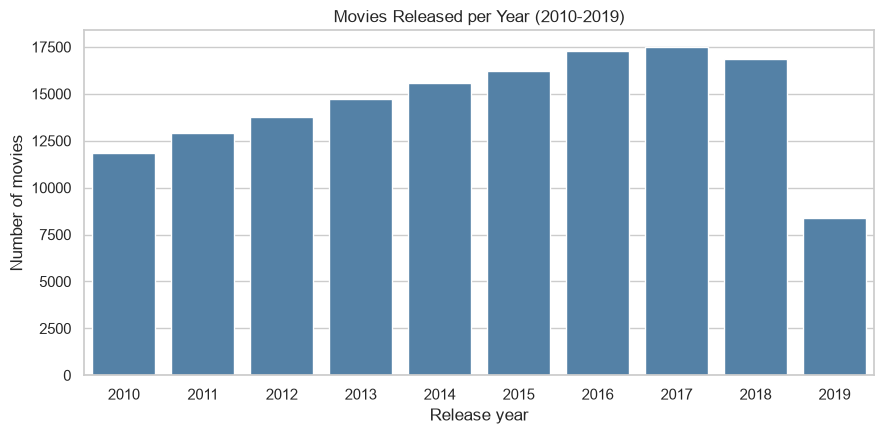

In [167]:
# Purpose: looking for a trend in production volume over time.
q_year = f"""
SELECT start_year, COUNT(*) AS movies
FROM movie_basics
WHERE start_year BETWEEN {START_YEAR} AND {END_YEAR}
GROUP BY start_year
ORDER BY start_year;
"""
df_year = pd.read_sql(q_year, conn4)
display(df_year)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_year, x="start_year", y="movies", color="steelblue")
plt.title("Movies Released per Year (2010-2019)")
plt.xlabel("Release year")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()

       runtime_minutes  averagerating    numvotes
count         65720.00       65720.00    65720.00
mean             94.73           6.32     3954.67
std             209.38           1.46    32088.23
min               3.00           1.00        5.00
25%              81.00           5.50       16.00
50%              91.00           6.50       62.00
75%             104.00           7.30      352.00
max           51420.00          10.00  1841066.00


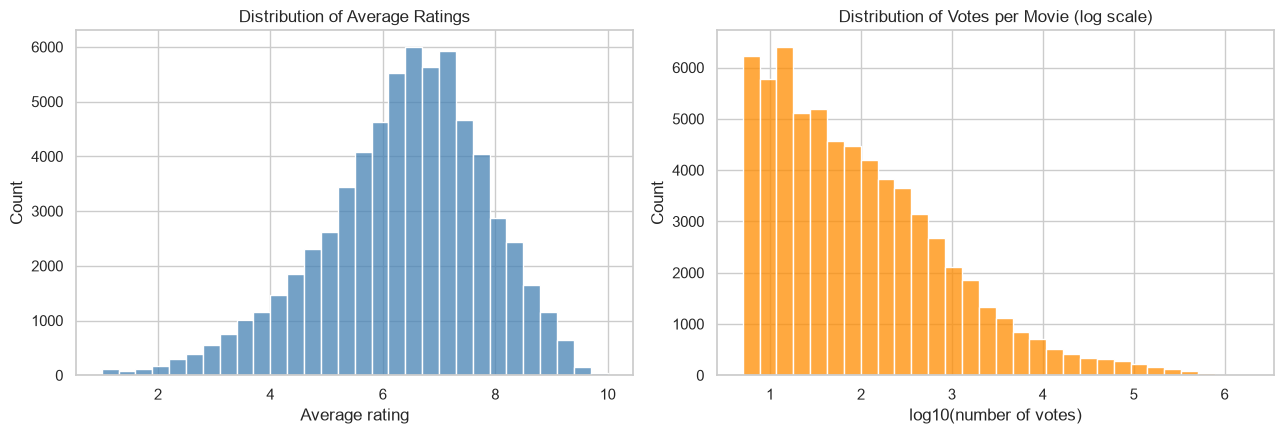

57.4% of rated movies have fewer than 100 votes.


In [168]:
# Purpose: understanding how ratings and vote counts are spread (and how reliable ratings are).
import numpy as np
print(df_movies[["runtime_minutes", "averagerating", "numvotes"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_movies["averagerating"], bins=30, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of Average Ratings")
axes[0].set_xlabel("Average rating")

sns.histplot(np.log10(df_movies["numvotes"]), bins=30, color="darkorange", ax=axes[1])
axes[1].set_title("Distribution of Votes per Movie (log scale)")
axes[1].set_xlabel("log10(number of votes)")
plt.tight_layout()
plt.show()

share_low = (df_movies["numvotes"] < MIN_VOTES).mean() * 100
print(f"{share_low:.1f}% of rated movies have fewer than {MIN_VOTES} votes.")

### Interpretation: ratings and votes
Ratings average 6.33 with a median of 6.5. The middle half of movies fall between 5.5 and 7.4, so ratings are left-skewed. Vote counts are extremely skewed: the median movie has only 49 votes and the maximum is about 1.84 million. A rating based on a handful of votes is unreliable, so the genre and runtime comparisons use movies with 100 or more votes.

In [169]:
# Purpose: keeping the  movies with enough votes and a plausible runtime. Rows are filtered, never filled.
df_reliable = df_movies[
    (df_movies["numvotes"] >= MIN_VOTES)
    & (df_movies["runtime_minutes"].between(MIN_RUNTIME, MAX_RUNTIME))
].copy()

print(f"Reliable subset: {len(df_reliable):,} of {len(df_movies):,} movies")

Reliable subset: 27,938 of 65,720 movies


,movies,avg_rating
runtime_band,,
<80,2830,5.75
80-100,14087,5.65
100-120,7076,6.18
120-150,3157,6.46
150+,788,6.61


Correlation between runtime and rating: 0.215


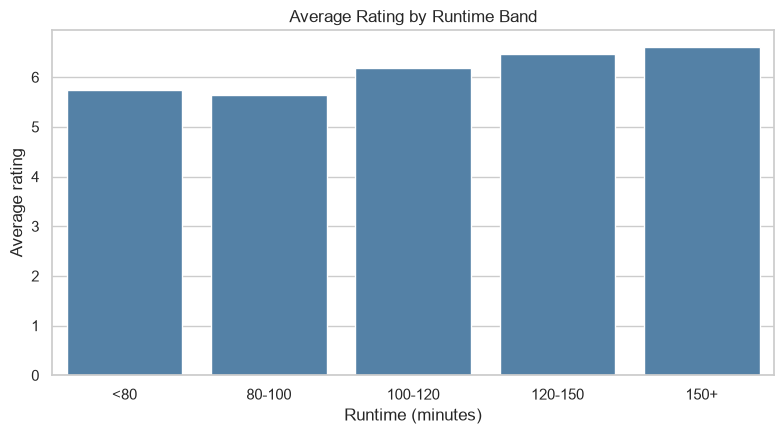

In [170]:
# Purpose: Testing whether longer movies tend to be rated higher.
df_reliable["runtime_band"] = pd.cut(
    df_reliable["runtime_minutes"],
    bins=[39, 80, 100, 120, 150, 300],
    labels=["<80", "80-100", "100-120", "120-150", "150+"],
)

runtime_summary = (
    df_reliable.groupby("runtime_band", observed=True)["averagerating"]
    .agg(movies="count", avg_rating="mean")
    .round(2)
)
display(runtime_summary)

corr = df_reliable["runtime_minutes"].corr(df_reliable["averagerating"])
print(f"Correlation between runtime and rating: {corr:.3f}")

plt.figure(figsize=(8, 4.5))
sns.barplot(x=runtime_summary.index, y=runtime_summary["avg_rating"], color="steelblue")
plt.title("Average Rating by Runtime Band")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Average rating")
plt.tight_layout()
plt.show()

### Interpretation: runtime
The median runtime is 91 minutes. Average rating rises with runtime: 5.75 (<80 min), 5.65 (80-100), 6.18 (100-120), 6.46 (120-150) and 6.61 (150+). The correlation of 0.215 is positive but modest, so longer movies tend to rate higher without runtime being a strong predictor. Longer movies may also attract a more committed audience, which could inflate their ratings.

In [171]:
# Purpose: genres are stored as comma-separated text, so split into one row per genre first.
df_genre = df_reliable.assign(genre=df_reliable["genres"].str.split(",")).explode("genre")

genre_summary = (
    df_genre.groupby("genre")
    .agg(movies=("movie_id", "nunique"),
         avg_rating=("averagerating", "mean"),
         median_votes=("numvotes", "median"))
    .query("movies >= @MIN_GENRE_MOVIES")
    .sort_values("avg_rating", ascending=False)
    .round(2)
)
genre_summary

,movies,avg_rating,median_votes
genre,,,
News,113,7.13,304.0
Documentary,3470,7.09,303.5
Biography,1437,6.89,928.0
Music,705,6.71,670.0
History,989,6.67,581.0
Sport,502,6.62,631.5
Animation,850,6.31,730.5
War,402,6.25,721.5
Musical,240,6.20,375.0


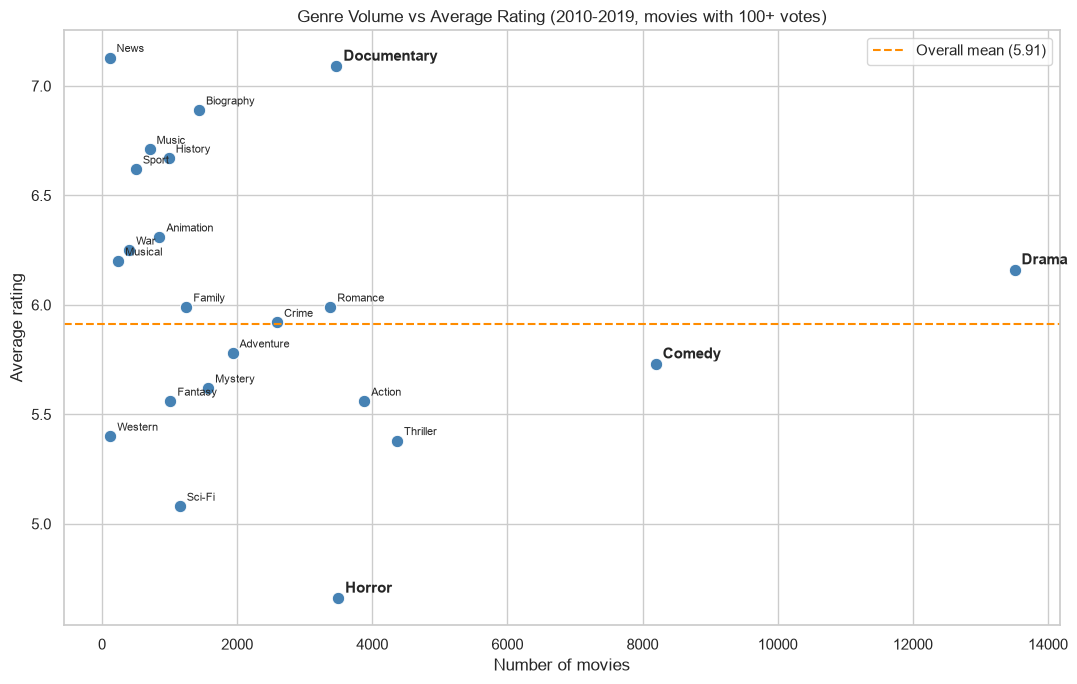

In [172]:
# Purpose: showing whether production volume is related to audience rating by genre.
highlight = ["Documentary", "Horror", "Drama", "Comedy"]
overall_mean = df_reliable["averagerating"].mean()

plt.figure(figsize=(11, 7))
sns.scatterplot(data=genre_summary, x="movies", y="avg_rating", s=80, color="steelblue")
for genre, row in genre_summary.iterrows():
    bold = genre in highlight
    plt.annotate(genre, (row["movies"], row["avg_rating"]), xytext=(5, 4),
                 textcoords="offset points",
                 fontsize=11 if bold else 8,
                 fontweight="bold" if bold else "normal")
plt.axhline(overall_mean, color="darkorange", linestyle="--", label=f"Overall mean ({overall_mean:.2f})")
plt.title("Genre Volume vs Average Rating (2010-2019, movies with 100+ votes)")
plt.xlabel("Number of movies")
plt.ylabel("Average rating")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation: genre volume vs rating
Volume and quality are not related. Drama (13,803) and Comedy (8,524) dominate production, yet Drama sits near the overall mean at 6.16 and Comedy below it at 5.70. Documentary (3,537 movies) and Horror (3,549) are produced in almost equal numbers, but Documentary averages 7.09 while Horror averages only 4.67, the lowest of all genres.

### Business question
**Which genres give a new film studio the best chance of producing a well-rated movie, and how should it weigh a genre's average rating against how crowded that genre already is?**

This question is relevant because a studio chooses genres before it spends money. It is specific because it can be answered with genre, rating and vote data. It stems from the pattern above: the most produced genres are not the best rated, and the most similar-sized genres show a 2.4-point rating gap.

In [173]:
# Purpose: confirming the Documentary vs Horror rating gap is not just noise (Mann-Whitney U test).
from scipy.stats import mannwhitneyu

doc = df_genre.loc[df_genre["genre"] == "Documentary", "averagerating"]
hor = df_genre.loc[df_genre["genre"] == "Horror", "averagerating"]

print(f"Documentary: n={len(doc):,}, mean={doc.mean():.2f}")
print(f"Horror:      n={len(hor):,}, mean={hor.mean():.2f}")

if len(doc) > 0 and len(hor) > 0:
    stat, p = mannwhitneyu(doc, hor, alternative="two-sided")
    print(f"Mann-Whitney U p-value: {p:.3g}")
else:
    print("One of the groups is empty, so the test was skipped.")

Documentary: n=3,470, mean=7.09
Horror:      n=3,496, mean=4.66
Mann-Whitney U p-value: 0


### Interpretation: is the Documentary-Horror gap real?
The Mann-Whitney U test compares the two rating distributions without assuming they are normal. A p-value below 0.05 means the gap is statistically significant and unlikely to be chance. Statistical significance does not prove that genre alone causes the difference. Documentaries may attract audiences who vote only when they care about the topic.

In [174]:
# Purpose: exploring who is behind highly rated movies (minimum 5 movies, 100+ votes each).
q_dir = f"""
SELECT p.primary_name AS director,
       COUNT(DISTINCT mb.movie_id)      AS movies,
       ROUND(AVG(mr.averagerating), 2)  AS avg_rating
FROM directors d
JOIN persons p        ON d.person_id = p.person_id
JOIN movie_basics mb  ON d.movie_id  = mb.movie_id
JOIN movie_ratings mr ON mb.movie_id = mr.movie_id
WHERE mb.start_year BETWEEN {START_YEAR} AND {END_YEAR}
  AND mr.numvotes >= {MIN_VOTES}
GROUP BY p.person_id
HAVING COUNT(DISTINCT mb.movie_id) >= {MIN_PERSON_MOVIES}
ORDER BY avg_rating DESC
LIMIT 10;
"""
pd.read_sql(q_dir, conn4)

,director,movies,avg_rating
0,Paul Dugdale,8,7.99
1,Denis Villeneuve,6,7.85
2,Mahesh Manjrekar,6,7.78
3,Monty Tiwa,5,7.70
4,Shoojit Sircar,5,7.66
5,Martin Scorsese,8,7.64
6,Keitarô Motonaga,6,7.62
7,Stephen Kijak,5,7.62
8,Angga Dwimas Sasongko,5,7.61
9,Morgan Neville,6,7.61


In [175]:
# Purpose:Using the  same analysis for writers, using the writers table.
q_wri = q_dir.replace("directors d", "writers d").replace("AS director", "AS writer")
pd.read_sql(q_wri, conn4)

,writer,movies,avg_rating
0,Jim Starlin,5,8.24
1,Christopher Nolan,5,8.16
2,Nick Lang,5,8.07
3,Matt Lang,5,8.07
4,Akiyoshi Hongo,6,7.78
5,Joe Simon,6,7.77
6,Michael Zimbalist,5,7.74
7,Jeff Zimbalist,5,7.74
8,Stephen McFeely,8,7.69
9,Christopher Markus,8,7.69


In [176]:
# Purpose: seeing which roles dominate the crew data and who appears most often as an actor.
q_cat = """
SELECT category, COUNT(*) AS credits
FROM principals
GROUP BY category
ORDER BY credits DESC;
"""
display(pd.read_sql(q_cat, conn4))

q_act = f"""
SELECT p.primary_name AS actor,
       COUNT(DISTINCT mb.movie_id)      AS movies,
       ROUND(AVG(mr.averagerating), 2)  AS avg_rating
FROM principals pr
JOIN persons p        ON pr.person_id = p.person_id
JOIN movie_basics mb  ON pr.movie_id  = mb.movie_id
JOIN movie_ratings mr ON mb.movie_id  = mr.movie_id
WHERE pr.category IN ('actor', 'actress')
  AND mb.start_year BETWEEN {START_YEAR} AND {END_YEAR}
  AND mr.numvotes >= {MIN_VOTES}
GROUP BY p.person_id
HAVING COUNT(DISTINCT mb.movie_id) >= {MIN_PERSON_MOVIES}
ORDER BY avg_rating DESC
LIMIT 10;
"""
pd.read_sql(q_act, conn4)

,category,credits
0,actor,256718
1,director,146393
2,actress,146208
3,producer,113724
4,cinematographer,80091
5,composer,77063
6,writer,74357
7,self,65424
8,editor,55512
9,production_designer,9373


,actor,movies,avg_rating
0,Sargun Mehta,6,8.40
1,Leonardo DiCaprio,9,8.09
2,Vishnu Manchu,8,7.92
3,Manoj Kumar Manchu,14,7.90
4,Rakshit Shetty,6,7.82
5,Mohan Babu,7,7.77
6,Kin Wah Chew,5,7.76
7,Mosharraf Karim,5,7.72
8,Vinayakan,5,7.70
9,Yui Horie,5,7.70


### Interpretation: personnel
Actors (256,718 credits) and actresses (146,208) are the largest credit groups, followed by directors, producers and writers. Directors and writers with at least 5 rated movies and 100+ votes per movie are ranked by average rating. A person with only a few movies can look exceptional by chance, so the minimum-movie rule keeps this ranking meaningful.

In [177]:
# Purpose: measure each issue so every cleaning task is backed by evidence.
q_quality = f"""
SELECT
  SUM(start_year > {END_YEAR})                                   AS years_after_2019,
  SUM(runtime_minutes < {MIN_RUNTIME})                           AS runtime_under_min,
  SUM(runtime_minutes > {MAX_RUNTIME})                           AS runtime_over_max,
  SUM(runtime_minutes IS NULL)                                   AS null_runtime,
  SUM(genres IS NULL)                                            AS null_genres,
  SUM(genres LIKE '%,%')                                         AS multi_genre_rows,
  SUM(primary_title <> original_title)                           AS title_differs
FROM movie_basics;
"""
quality = pd.read_sql(q_quality, conn4).T.rename(columns={0: "count"})
display(quality)

q_unrated = f"""
SELECT COUNT(*) AS movies_without_rating
FROM movie_basics mb
LEFT JOIN movie_ratings mr ON mb.movie_id = mr.movie_id
WHERE mb.start_year BETWEEN {START_YEAR} AND {END_YEAR}
  AND mr.movie_id IS NULL;
"""
display(pd.read_sql(q_unrated, conn4))

q_dups = """
SELECT COUNT(*) AS duplicate_title_year_pairs FROM (
  SELECT primary_title, start_year
  FROM movie_basics
  GROUP BY primary_title, start_year
  HAVING COUNT(*) > 1
);
"""
pd.read_sql(q_dups, conn4)

,count
years_after_2019,1063
runtime_under_min,5211
runtime_over_max,123
null_runtime,31739
null_genres,5408
multi_genre_rows,59378
title_differs,14483


,movies_without_rating
0,71225


,duplicate_title_year_pairs
0,1870


In [178]:
# Purpose: summarizing every issue found, the evidence, and the proposed fix.
cleaning_tasks = pd.DataFrame([
    ["Null handling",   "runtime_minutes and genres contain nulls",         "Exclude or flag these rows; do not impute"],
    ["Validity",        "start_year goes beyond 2019 (up to 2115)",         "Filter to 2010-2019"],
    ["Outliers",        "Runtimes from 3 to 51,420 minutes",                f"Keep {MIN_RUNTIME}-{MAX_RUNTIME} minutes or review manually"],
    ["Reliability",     "Median movie has very few votes",                  f"Require at least {MIN_VOTES} votes for rating analysis"],
    ["Normalization",   "genres stored as comma-separated text",            "Split into one row per movie-genre pair"],
    ["Standardization", "actor and actress are separate categories",        "Merge into a single performer category; separate self / archive roles"],
    ["Coverage",        "Many movies have no rating record",                "Decide to exclude unrated movies or report them separately"],
    ["Duplicates",      "Repeated title/year pairs; title differs from original", "Deduplicate and standardize titles (case, whitespace)"],
    ["Data types",      "IDs are text; years and runtimes need numeric types", "Cast types and validate on load"],
], columns=["Task type", "Issue found", "Proposed action"])
cleaning_tasks

,Task type,Issue found,Proposed action
0,Null handling,runtime_minutes and genres contain nulls,Exclude or flag these rows; do not impute
1,Validity,start_year goes beyond 2019 (up to 2115),Filter to 2010-2019
2,Outliers,"Runtimes from 3 to 51,420 minutes",Keep 40-300 minutes or review manually
3,Reliability,Median movie has very few votes,Require at least 100 votes for rating analysis
4,Normalization,genres stored as comma-separated text,Split into one row per movie-genre pair
5,Standardization,actor and actress are separate categories,Merge into a single performer category; separa...
6,Coverage,Many movies have no rating record,Decide to exclude unrated movies or report the...
7,Duplicates,Repeated title/year pairs; title differs from ...,"Deduplicate and standardize titles (case, whit..."
8,Data types,IDs are text; years and runtimes need numeric ...,Cast types and validate on load


## Summary: Conclusion 
### 1. Production volume does not predict audience approval
**What we found:** Drama (13,803 movies) and Comedy (8,524) are the most produced genres, yet their average ratings (6.16 and 5.70) sit at or below the overall average of 6.33.
**What the company should do:** Do not choose a genre simply because it is popular to make. In crowded genres such as Drama and Comedy, compete on a distinctive story, strong talent or a clear niche, because the genre alone will not earn higher ratings.

### 2. Some genres are consistently better received than others
**What we found:** Documentary (7.09), Biography (6.88) and History (6.67) are among the highest-rated genres, and Documentary has substantial volume (3,537 movies), so its rating is not a small-sample effect. Horror (4.67) is the lowest, even though it is produced in almost the same numbers as Documentary (3,549).
**What the company should do:** Make well-rated genres the first area to explore and test. Enter Horror, Sci-Fi and Thriller only when there is a specific creative or commercial reason, since earning strong ratings there is harder.

### 3. The best-rated genres reach smaller audiences
**What we found:** Documentary's median is about 298 votes per movie, compared with roughly 1,000 for Crime and Action.
**What the company should do:** Decide whether the goal is critical approval or broad reach. A studio that picks high-rated genres should pair them with a distribution and marketing plan that builds the audience, and one that wants reach should balance them with higher-engagement genres.

### 4. Longer movies tend to rate slightly higher
**What we found:** Ratings rise from 5.65 for 80–100 minutes to 6.61 for 150+ minutes, but the correlation (0.215) is modest.
**What the company should do:** Let the story set the runtime. Do not lengthen a movie to chase ratings, and test runtime within a genre before treating it as a lever.

### 5. A small group of people is linked to consistently well-rated work
**What we found:** Directors, writers and actors with at least five movies and strong average ratings stand out in the data.
**What the company should do:** Use these names as a shortlist for partnership conversations, checking availability, cost and fit, since the rankings rest on a limited number of titles per person.

### 6. The data has gaps that limit how far we can go
**What we found:** About a fifth of runtimes and a small share of genres are missing, release years reach 2115, runtimes range from 3 to 51,420 minutes, and the typical movie has only 49 votes.
**What the company should do:** Before scaling this analysis, apply the cleaning tasks listed above in a repeatable process, and always require a minimum number of votes before trusting a rating.

### Overall recommendation
To scale, the studio should **build a balanced portfolio**: a core of well-rated genres (Documentary, Biography, History), complemented by a few higher-volume genres where it has a clear creative edge. This spreads risk while it learns what its own audience wants. The next step is to **add budget and revenue data**, so that ratings can be connected to profit, and to **run the deeper analysis** on genre combinations, runtime and release year once the data is cleaned.


In [179]:
# Purpose: release the database file when the analysis is finished.
conn4.close()